# Preparación inicial
*(Etapa: Ingest -> Data Lake)*

Generación de archivos que servirán como fuente de datos.

Se toman las descargas disponibles de Tramos y Calificaciones CCTV y se unifican en una sola fuente de datos para posterior procesamiento y depuración.

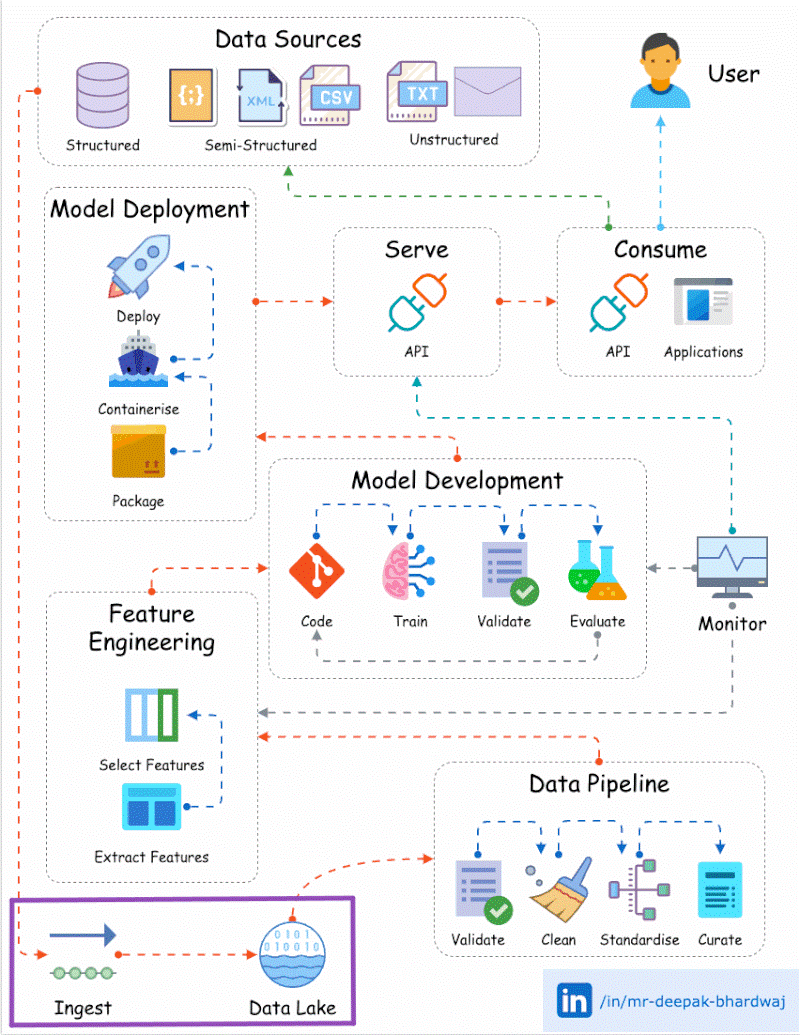

In [1]:
# Bibliotecas

import pandas as pd
import glob as gl

In [2]:
# Definiciones globales

%run ../Lib/pandas_options.py
%run ../Lib/define_constantes.py

# Archivo de tramos de tubería.

La selección de las columnas en el archivo de tramos se establece desde la descarga. El origen es el sistema SIG GEOMEDIA.

Se esperan las siguientes:

1. DIAMETRO
2. CAMARA_CAI
3. CONEXIONES
4. MATERIAL
5. TUBERIA_EL
6. VIDA_UTIL
7. FABRICANTE
8. TIPO_CIMEN
9. TIPO_SUELO
10. TIPO_RED
11. PROF_BATEA
12. PROF_BATE1
13. COTA_BATEA
14. COTA_BATE1
15. IPID
16. ESTADO
17. GRUPO
18. PROPIETARI
19. OPERADOR
20. EMPRESA
21. COD_MUNICI
22. COD_DEPART
23. COD_PAIS
24. LONGITUD
25. ARRANQUE
26. TIPO_AGUA
27. CUENCA
28. CONDICION_
29. DIAMETRO_I
30. MATERIAL_R
31. NOMBRE_COL
32. PENDIENTE
33. PROFUNDIDA
34. CAUDAL_TUB
35. CAUDAL_DIS
36. COEFICIENT
37. OBSERVACIO
38. UBICACION
39. FECHA_INST
40. COOR_LAT
41. COOR_LON
42. ESTADO_OPE
43. PAIS
44. DEPARTAMEN
45. MUNICIPIO
46. CODIGO_ARE
47. ZONA
48. CUENCA_HID


In [3]:
# Cargar archivo de tramos de tubería a un dataframe de PANDAS

archivo_tramos = f'{DIRECTORIO_DATOS}/DATOSTRAMOS_2024-10.csv'
df_tramos = pd.read_csv(archivo_tramos, low_memory=False)

In [4]:
# Visualizar resultado de la carga de tramos

print(df_tramos.columns)

Index(['G3E_STYLEI,N,10,0', 'G3E_FNO,N,10,0', 'G3E_CNO,N,10,0', 'G3E_FID,N,10,0', 'G3E_CID,N,5,0', 'G3E_ID,N,10,0', 'DIAMETRO,N,10,0', 'CAMARA_CAI,C,255', 'CONEXIONES,C,255', 'MATERIAL,C,255', 'TUBERIA_EL,C,255', 'VIDA_UTIL,N,5,0', 'FABRICANTE,C,255', 'TIPO_CIMEN,C,255', 'TIPO_SUELO,C,255', 'TIPO_RED,C,255', 'PROF_BATEA,N,24,5', 'PROF_BATE1,N,24,5', 'COTA_BATEA,N,24,5', 'COTA_BATE1,N,24,5', 'IPID,N,10,0', 'ESTADO,C,255', 'GRUPO,C,255', 'PROPIETARI,C,255', 'OPERADOR,C,255', 'EMPRESA,C,255', 'COD_MUNICI,C,255', 'COD_DEPART,C,255', 'COD_PAIS,C,255', 'CONDICION_,C,255', 'SUBESTADO,C,255', 'LONGITUD,N,24,5', 'ARRANQUE,C,255', 'TIPO_AGUA,C,255', 'CUENCA,C,255', 'DIAMETRO_I,N,24,5', 'MATERIAL_R,C,50', 'NOMBRE_COL,C,50', 'PENDIENTE,N,24,5', 'PROFUNDIDA,N,24,5', 'CAUDAL_TUB,N,24,5',
       'CAUDAL_DIS,N,24,5', 'COEFICIENT,N,24,5', 'CODIGO_TV,C,30', 'NIT_DV,C,20', 'NUMERO_CER,C,50', 'NUMERO_LOT,C,25', 'ENTIDAD_CE,C,50', 'CONSTRUCTO,C,50', 'POLIZA,C,50', 'FECHA_INIC,D', 'PLAZO,C,50', 'OBSERVACIO,

In [5]:
# Corregir nombres de columnas 

df_tramos.columns = [col.split(',')[0] for col in df_tramos.columns]
print(df_tramos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221024 entries, 0 to 221023
Data columns (total 79 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   G3E_STYLEI  221024 non-null  int64  
 1   G3E_FNO     221024 non-null  int64  
 2   G3E_CNO     221024 non-null  int64  
 3   G3E_FID     221024 non-null  int64  
 4   G3E_CID     221024 non-null  int64  
 5   G3E_ID      221024 non-null  int64  
 6   DIAMETRO    221024 non-null  int64  
 7   CAMARA_CAI  221024 non-null  object 
 8   CONEXIONES  199642 non-null  object 
 9   MATERIAL    220587 non-null  object 
 10  TUBERIA_EL  206776 non-null  object 
 11  VIDA_UTIL   207362 non-null  float64
 12  FABRICANTE  203489 non-null  object 
 13  TIPO_CIMEN  91060 non-null   object 
 14  TIPO_SUELO  72833 non-null   object 
 15  TIPO_RED    221024 non-null  object 
 16  PROF_BATEA  218241 non-null  float64
 17  PROF_BATE1  218048 non-null  float64
 18  COTA_BATEA  216747 non-null  float64
 19  CO

In [6]:
# Cargar datos de CCTV (Pueden ser varios archivos)

lista_archivos_cctv = gl.glob(f'{DIRECTORIO_DATOS}/DATOSCCTV_TODO_*.csv')

# Solo se requiere Ipid, GradoCalificacionPrincipal y Fecha
lista_dfs_cctv = [
    pd.read_csv(
        archivo,
        usecols=['Ipid', 'GradoCalificacionPrincipal', 'Fecha'],
    ) for archivo in lista_archivos_cctv
]

print([df.info() for df in lista_dfs_cctv])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29222 entries, 0 to 29221
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Ipid                        29222 non-null  int64  
 1   GradoCalificacionPrincipal  28859 non-null  float64
 2   Fecha                       29222 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 685.0+ KB
[None]


In [7]:
# Unificar dataframes de CCTV en uno solo y renombrar coiumnas

df_calificaciones = pd.concat(lista_dfs_cctv).rename(
    columns={'Ipid': 'IPID', 'GradoCalificacionPrincipal': 'CALIFICACION', 'Fecha': 'FECHA_CALIFICACION'}
)

print(df_calificaciones.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29222 entries, 0 to 29221
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   IPID                29222 non-null  int64  
 1   CALIFICACION        28859 non-null  float64
 2   FECHA_CALIFICACION  29222 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 685.0+ KB
None


In [8]:
# Eliminar filas de calificaciones con datos nulos o con calificacion 0

df_calificaciones = df_calificaciones.dropna()
df_calificaciones = df_calificaciones[df_calificaciones['CALIFICACION'] > 0]
print(df_calificaciones.info())

<class 'pandas.core.frame.DataFrame'>
Index: 28853 entries, 0 to 29221
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   IPID                28853 non-null  int64  
 1   CALIFICACION        28853 non-null  float64
 2   FECHA_CALIFICACION  28853 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 901.7+ KB
None


In [9]:
# Separar datos fe validación

df_validacion = df_calificaciones.sample(n=150)

# Eliminar datos de validacion 
df_calificaciones_sin_validaciones = df_calificaciones.drop(df_validacion.index)

print(df_validacion.info())
print(df_calificaciones_sin_validaciones.info())

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 2983 to 10241
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   IPID                150 non-null    int64  
 1   CALIFICACION        150 non-null    float64
 2   FECHA_CALIFICACION  150 non-null    object 
dtypes: float64(1), int64(1), object(1)
memory usage: 4.7+ KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 28703 entries, 0 to 29221
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   IPID                28703 non-null  int64  
 1   CALIFICACION        28703 non-null  float64
 2   FECHA_CALIFICACION  28703 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 897.0+ KB
None


In [10]:
# Consolidar tramos con calificaciones

df_tramos_calificados = df_tramos.merge(df_calificaciones_sin_validaciones, on='IPID')
print(df_tramos_calificados.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27920 entries, 0 to 27919
Data columns (total 81 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   G3E_STYLEI          27920 non-null  int64  
 1   G3E_FNO             27920 non-null  int64  
 2   G3E_CNO             27920 non-null  int64  
 3   G3E_FID             27920 non-null  int64  
 4   G3E_CID             27920 non-null  int64  
 5   G3E_ID              27920 non-null  int64  
 6   DIAMETRO            27920 non-null  int64  
 7   CAMARA_CAI          27920 non-null  object 
 8   CONEXIONES          25763 non-null  object 
 9   MATERIAL            27917 non-null  object 
 10  TUBERIA_EL          27545 non-null  object 
 11  VIDA_UTIL           27375 non-null  float64
 12  FABRICANTE          27875 non-null  object 
 13  TIPO_CIMEN          12907 non-null  object 
 14  TIPO_SUELO          12293 non-null  object 
 15  TIPO_RED            27920 non-null  object 
 16  PROF

In [11]:
# Guardar consolidación de tramos calificados y datos de validacion

archivo_tramos_calificados = f'{DIRECTORIO_RESULTADOS}/TRAMOSCALIFICADOS_2024-11.csv'
df_tramos_calificados.to_csv(archivo_tramos_calificados, index=False)

archivo_validacion = f'{DIRECTORIO_RESULTADOS}/DATOSCCTV_VALIDACION_2024-11.csv'
df_validacion.to_csv(archivo_validacion, index=False)